In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import io

df=pd.read_csv('heart.csv')
print(df)

df.isnull().sum() #checking for null values

df.fillna(df.mean(), inplace=True)  # Replace missing values with the mean of each column

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['age', 'thalachh']] = scaler.fit_transform(df[['age', 'thalachh']])


     age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0     63    1   3     145   233    1        0       150     0      2.3    0   
1     37    1   2     130   250    0        1       187     0      3.5    0   
2     41    0   1     130   204    0        0       172     0      1.4    2   
3     56    1   1     120   236    0        1       178     0      0.8    2   
4     57    0   0     120   354    0        1       163     1      0.6    2   
..   ...  ...  ..     ...   ...  ...      ...       ...   ...      ...  ...   
298   57    0   0     140   241    0        1       123     1      0.2    1   
299   45    1   3     110   264    0        1       132     0      1.2    1   
300   68    1   0     144   193    1        1       141     0      3.4    1   
301   57    1   0     130   131    0        1       115     1      1.2    1   
302   57    0   1     130   236    0        0       174     0      0.0    1   

     caa  thall  output  
0      0      1       1  

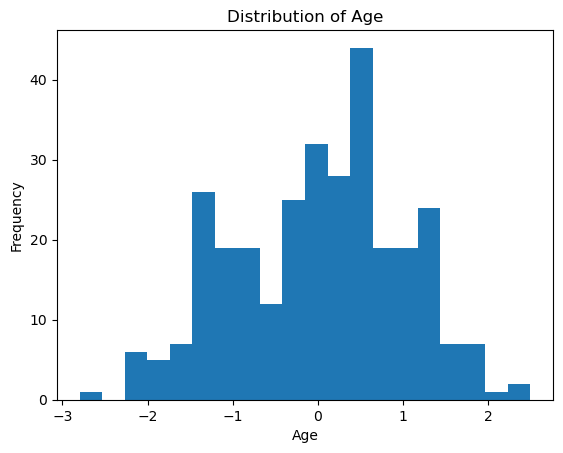

cp          0.125931
caa         0.121937
thall       0.105037
exng        0.103193
oldpeak     0.087135
thalachh    0.087067
age         0.071300
slp         0.070765
trtbps      0.062047
chol        0.059300
sex         0.053396
restecg     0.033300
fbs         0.019592
dtype: float64


In [2]:
#fitting the data into model

plt.hist(df['age'], bins=20)
plt.xlabel('Age')                   
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.show()            #graphical representation of Age & frequency

X = df.drop('output', axis=1)  # Features 
y = df['output']  # Target variable 

from sklearn.ensemble import ExtraTreesClassifier

model = ExtraTreesClassifier() #ML model
model.fit(X, y) #fit the data

# Print feature importances
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
feature_importances.sort_values(ascending=False, inplace=True)
print(feature_importances)
# Select top k features (e.g., top 5 features)
k = 5


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Select top-k important features
selected_features = feature_importances.index[:k].tolist()
X_selected = X_scaled[:, :k]  # Assuming X is ordered by feature_importances

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)

# Train Logistic Regression with increased max_iter
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred = logistic_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Print selected features and performance metrics
print("Selected features:", selected_features)
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")

Selected features: ['cp', 'caa', 'thall', 'exng', 'oldpeak']
Accuracy: 0.787
Precision: 0.852
Recall: 0.719
F1 Score: 0.780


Logistic Regression:
Accuracy: 0.8524590163934426
Precision: 0.8709677419354839
Recall: 0.84375
F1 Score: 0.8571428571428571


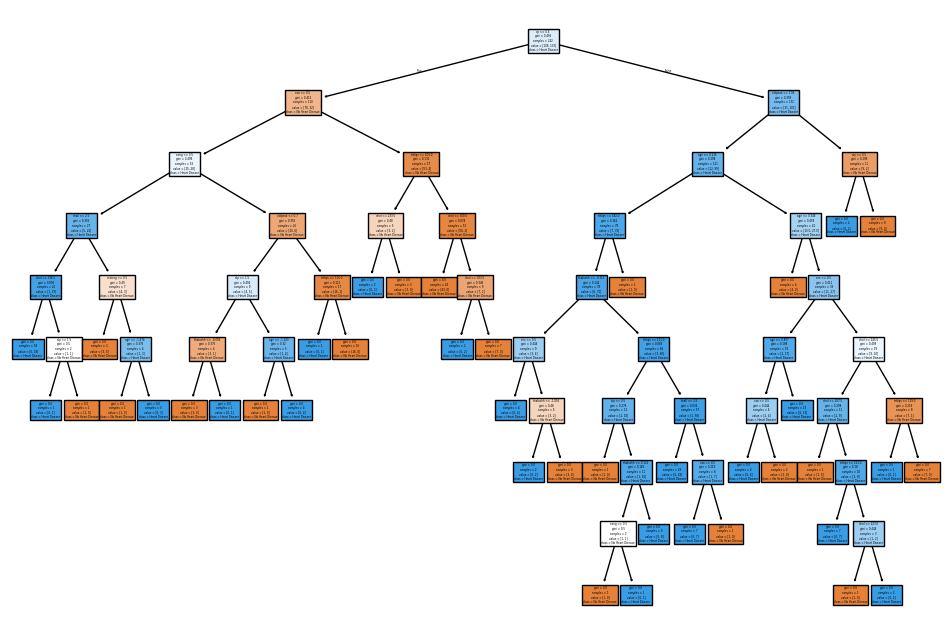

In [4]:
print("Logistic Regression:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Train the Decision Tree model
tree_model = DecisionTreeClassifier() 
tree_model.fit(X_train, y_train)

# Plot the decision tree
plt.figure(figsize=(12, 8))
tree.plot_tree(tree_model, feature_names=X.columns, class_names=['No Heart Disease', 'Heart Disease'], filled=True)
plt.show()
